# 02 — QC, Normalization, Statistical Modeling, PCA & Machine Learning (Steps 1–4)

**Project:** 27200 Data-driven Bioengineering — Dataset ME2 (*Omeprazole vs DMSO in the Com20 synthetic gut bacterial community over T0–T8, hourly 0–8 h*).  
**Course tools integrated:** Week 4 (Experimental Design, Confounders, Multiple-Testing Correction, PERMANOVA), Week 8 (Untargeted LC-MS/MS QC, Blank/QC Filtering, PQN vs TIC, ESI Ion Suppression), Week 9 (PCA, K-means Kinetic Clustering, Supervised Random Forest & Regularized Logistic Regression).

> **Reproducibility note:** All processed datasets and summary tables loaded here are generated deterministically by `src/pipeline.py`, and high-resolution figures by `src/make_figures.py`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

PROC = ROOT / "data" / "processed"
TABLES = ROOT / "results" / "tables"
FIGS = ROOT / "results" / "figures"

meta = pd.read_csv(PROC / "sample_qc_summary.csv")
res = pd.read_csv(TABLES / "table02_statistical_results_all.csv", index_col="row_id")
perm = pd.read_csv(TABLES / "table09_permanova_variance_partitioning.csv")
ml_cv = pd.read_csv(TABLES / "table08b_ml_cv_performance.csv")
ml_rank = pd.read_csv(TABLES / "table08_ml_feature_ranking.csv", index_col="row_id")
with open(PROC / "analysis_summary.json") as f:
    summary = json.load(f)

print(f"Loaded {len(meta)} injections and {len(res)} filtered features ({summary['n_unique_iimn_entities']} IIMN-collapsed unique entities).")

Loaded 69 injections and 3414 filtered features (1814 IIMN-collapsed unique entities).


## Step 1 — Know Your Design: Failed Injections & LC-MS Run-Order Confounding

Three critical experimental-design findings emerge immediately from auditing `group2_drugs_metadata.csv` and `group2_drugs_iimn_gnps_quant.csv`:

1. **Feature count discrepancy (4,525 vs 6,993 in `docs/data_description.pdf`):** `row ID` spans `16` to `11,816` because this table is a subset of the 12-drug Com20 study (Pakkir Shah et al., 2026), retaining features detected in the Omeprazole/DMSO/Medium/Blank/QC injections. Consequently, **Pooled QCs** were pooled across all 12 study drugs (even containing `erythromycin`, `ID 4135`), which dilutes Omeprazole-specific products ~12-fold and means Pooled QCs **must not** be used as a strict presence filter (629/1,060 Omeprazole-specific features are absent from Pooled QCs).
2. **Four failed / blank-like bacterial injections:** `T4_DMSO_Bac_rep3`, `T4_Omepr_Bac_rep3`, `T5_DMSO_Bac_rep3`, and `T5_Omepr_Bac_rep2` show TIC = `4.4–4.7 × 10⁷` (**lower than all 4 solvent blanks**, `6.4–9.0 × 10⁷`) and correlate `r = 0.83–0.89` with Blanks vs `r = 0.21–0.40` with true replicates. Three occurred back-to-back within 30 minutes (`2024-07-04 00:09–00:38`). Removing them leaves `n = 50` valid bacterial injections (`n = 2` at T4/T5, `n = 3` at all other timepoints).
3. **LC-MS acquisition run-order confounding (`run_date`, July 2–7, 5.3 days):** Biological timepoint correlates negatively with run order (`Spearman r = -0.474, p = 0.017` in DMSO; `r = -0.427, p = 0.033` in Omeprazole) because T4/T5/T8 were injected on Days 1–2 while T1/T2/T6 ran on Days 5–6. Crucially, **parent Omeprazole (`ID 2828`) is acid-labile and decays in the autosampler queue (`r = -0.620, p = 0.0009`)**, dropping completely to `0` in T1 and T2 (injected last on Day 5–6), whereas its reduced microbial product **Ufiprazole (`ID 2962`)** tracks biological incubation time cleanly (`r = +0.976, p < 10⁻¹⁴`).

,filename,sample_type,drug,TIC,n_nonzero,frac_zero,mean_corr_to_blanks,run_date
47,T5_DMSO_Bac_rep3.mzML,T5,DMSO,4.429704e+07,834,0.815691,0.866071,2024-07-04T00:09:02
42,T4_DMSO_Bac_rep3.mzML,T4,DMSO,4.494867e+07,842,0.813923,0.870738,2024-07-03T14:57:46
50,T5_Omepr_Bac_rep2.mzML,T5,Omeprazole,4.605796e+07,813,0.820331,0.871196,2024-07-04T00:38:35
46,T4_Omepr_Bac_rep3.mzML,T4,Omeprazole,4.674859e+07,836,0.815249,0.867663,2024-07-04T00:28:45
4,Blank_4.mzML,Blank,Blank,6.382349e+07,886,0.804199,0.952133,2024-07-03T05:45:51
6,Blank_3.mzML,Blank,Blank,6.496478e+07,848,0.812597,0.947824,2024-07-03T00:40:13
7,Blank_2.mzML,Blank,Blank,8.161792e+07,981,0.783204,0.942984,2024-07-02T18:15:40
5,Blank_1.mzML,Blank,Blank,9.014239e+07,788,0.825856,0.925956,2024-07-02T10:17:20


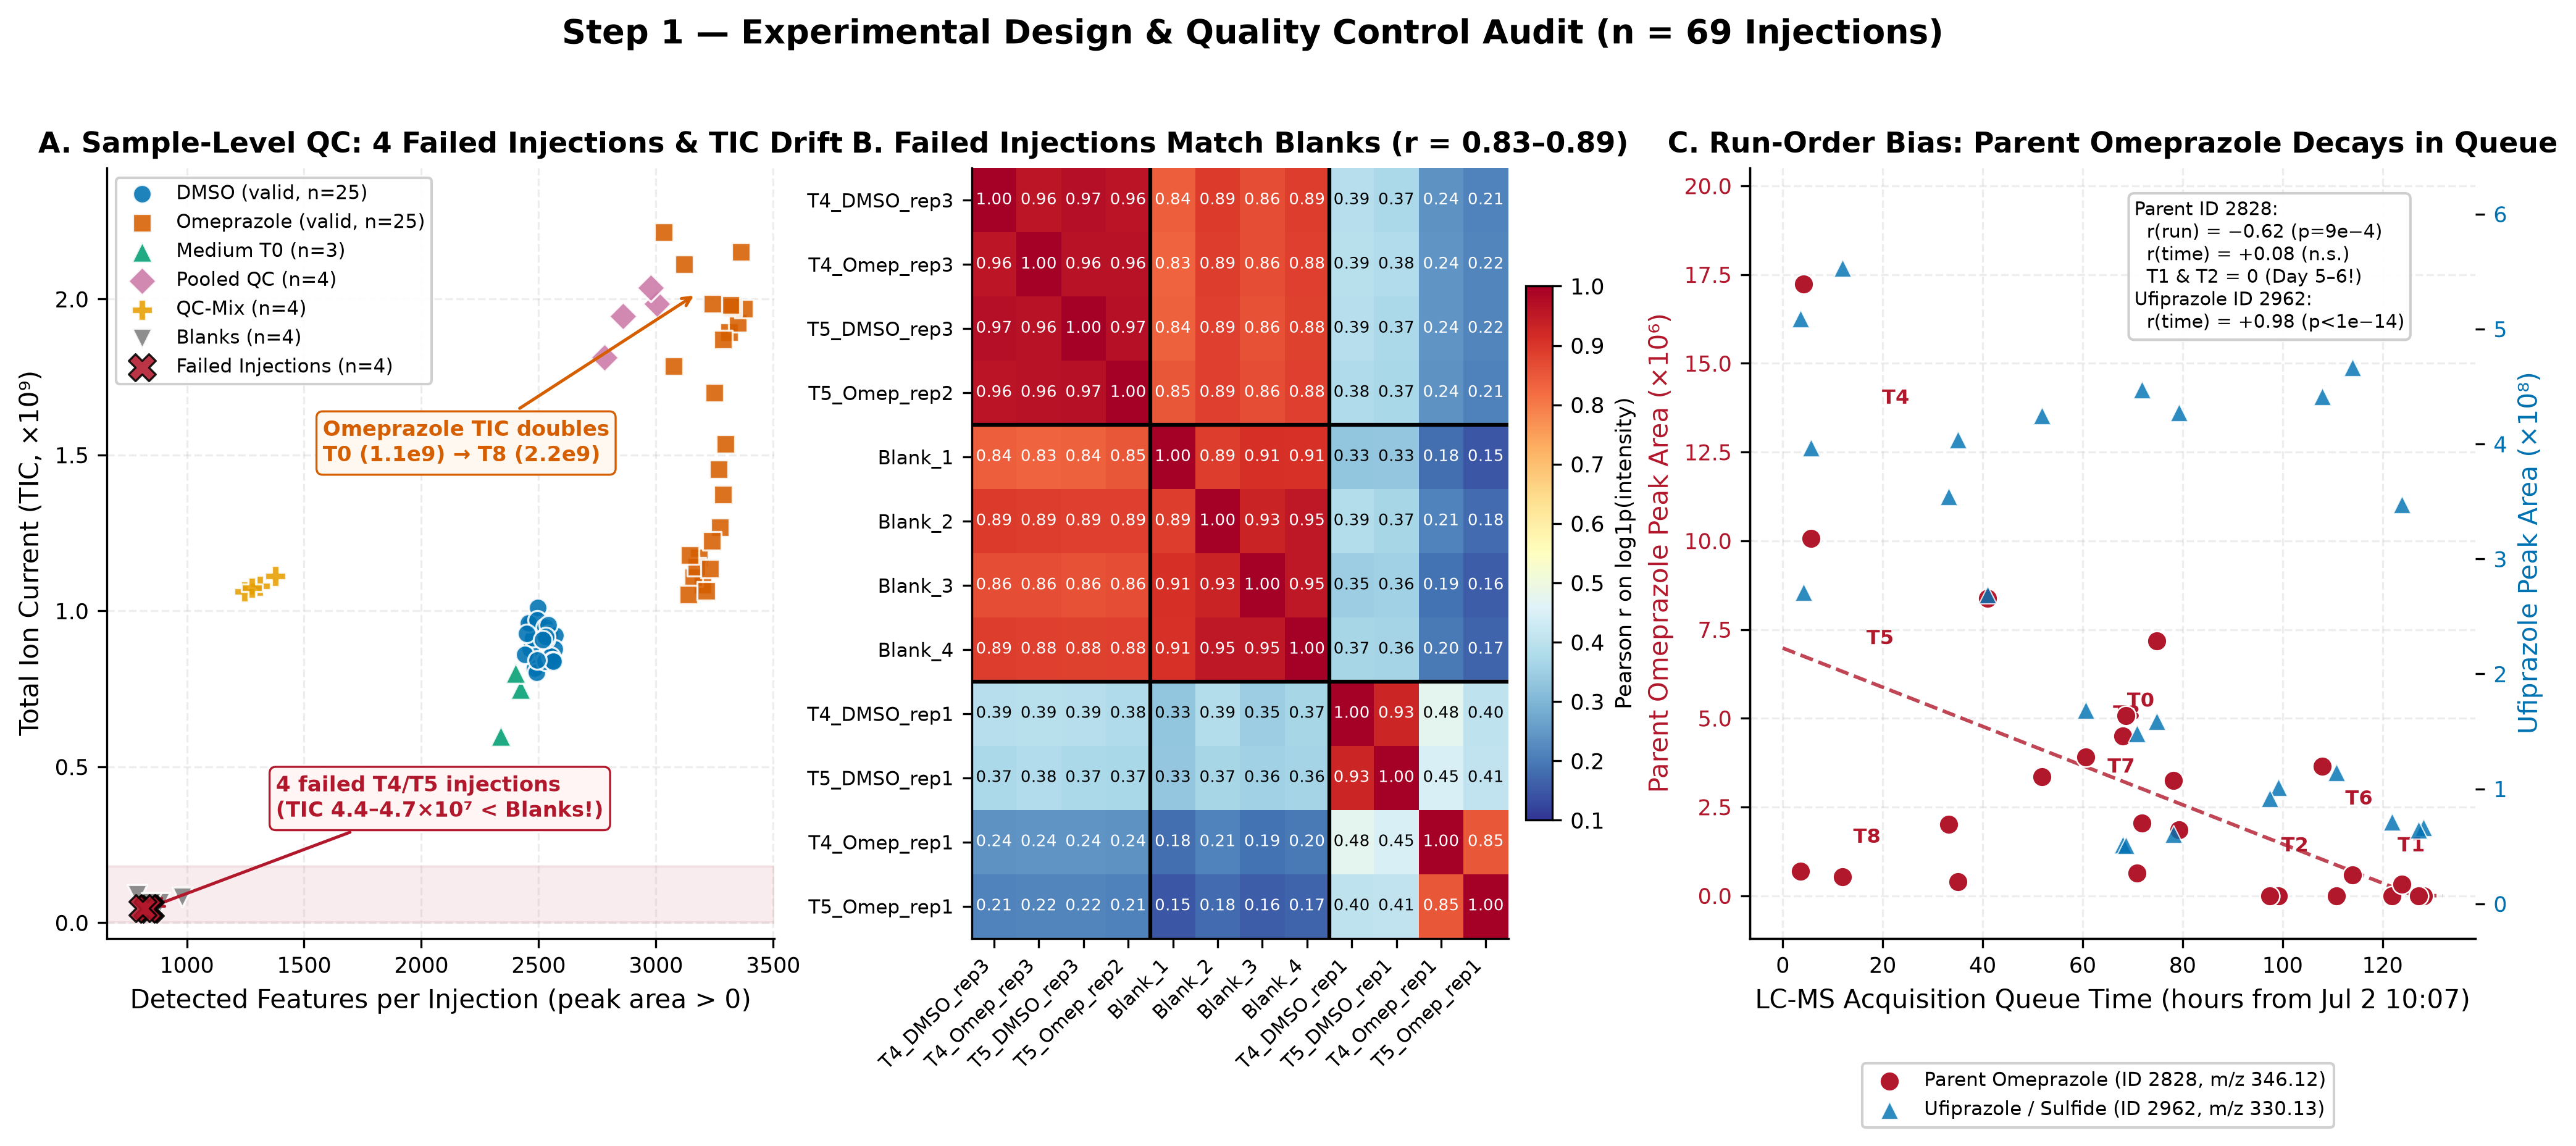

In [2]:
failed_tbl = meta[meta["is_failed_injection"] | (meta["mzmine_sample_type"] == "blank")][
    ["filename", "sample_type", "drug", "TIC", "n_nonzero", "frac_zero", "mean_corr_to_blanks", "run_date"]
].sort_values("TIC")
display(failed_tbl)
display(Image(filename=str(FIGS / "fig01_qc_failed_injections_and_run_order.png"), width=1050))

## Step 2 — Filtering, PQN vs TIC Normalization & ESI Ion Suppression

- **Filtering:** Retaining features detected in `≥ 2` replicates of at least one `Treatment × Timepoint` group (`3,882`) and with maximum group mean `> 3×` mean Blank intensity yields **`3,414` high-confidence features** (`1,814` unique molecular entities after collapsing IIMN `correlation group ID` adducts/fragments).
- **Why PQN instead of TIC normalization?** Ufiprazole (`ID 2962`) and its co-eluting IIMN fragments/isotopes (`cg=220`) surge 9-fold from T0 to T8, reaching ~47% of total ion current and nearly **doubling** Omeprazole sample TIC (`1.05× → 1.99×`) while DMSO TIC remains flat. Blind TIC normalization divides every endogenous metabolite in late Omeprazole samples by ~2×, fabricating **`1,780 / 2,146` (83%)** false down-regulated shared features (`1,387` false negative `Trt × Time` interactions). **Probabilistic Quotient Normalization (PQN)** anchored to `1,902` ubiquitous DMSO features remains flat (`0.84–1.05×`) and eliminates this compositional artifact.
- **Measurement Constraint Discovery — Co-elution ESI Ion Suppression (`RT 1.80–2.25 min`):** Even after PQN normalization, `114 / 172` (**66.3%**) of all significant negative `Treatment × Time` interactions among shared endogenous features fall inside the narrow **`RT 1.80–2.25 min`** elution/tailing window of the overloaded `4.9 × 10⁸` Ufiprazole peak (`RT = 1.90 min`), despite that window containing only `9.0%` of shared features (**Odds Ratio = `46.5`, Fisher's exact `p = 2.1 × 10⁻⁹¹`**). Examples like `N-Phenethylacetamide (ID 2972, RT 1.87)` and `IPA isomer (ID 3178, RT 2.00)` are suppressed to zero as Ufiprazole grows—proving we must flag `RT 1.80–2.25 min` when interpreting endogenous depletions.

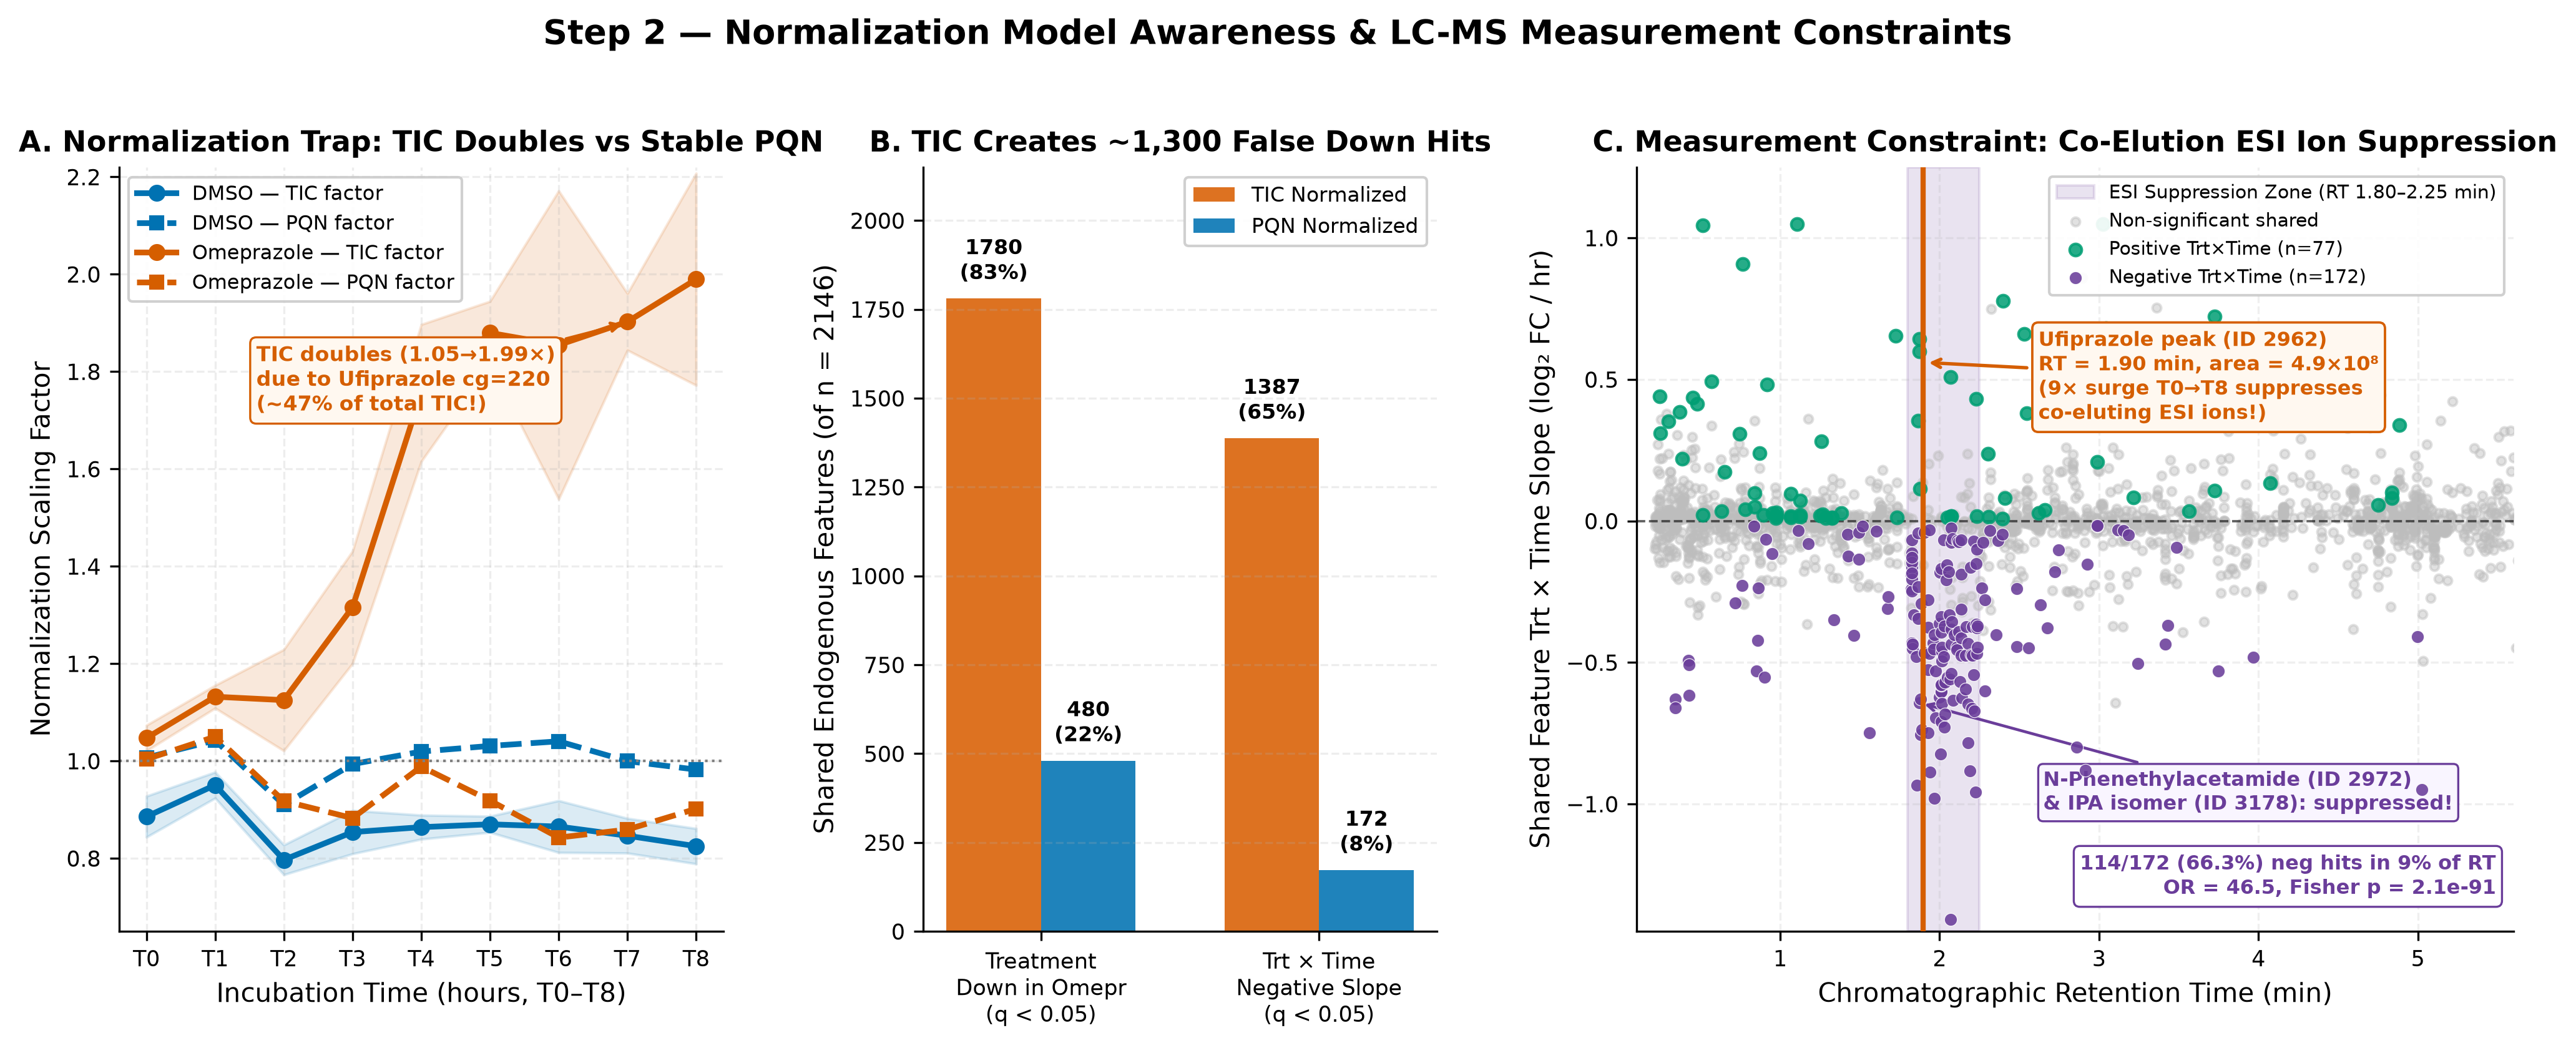

In [3]:
display(Image(filename=str(FIGS / "fig02_normalization_pqn_vs_tic_and_ion_suppression.png"), width=1050))

## Steps 3 & 4 — Statistical Modeling, PCA, PERMANOVA, Kinetic Modules & ML Prioritization

We combine **two complementary statistical models** (BH-FDR `q < 0.05`) plus **multivariate PERMANOVA (`999` permutations)** and **Machine Learning (Week 9)**:

1. **Run-order-adjusted linear model (`log₂ PQN ~ Treatment + Time + Treatment:Time + RunOrder`):** Separates linear temporal slopes and treatment effects while controlling for acquisition queue drift (`526` features show `q_run < 0.05`).
2. **Two-way Categorical ANOVA (`log₂ PQN ~ Treatment * factor(Time)`):** Captures **non-linear / transient intermediates** (`+774` additional `Trt × Time` hits missed by linear slopes, such as `ID 4470` and `ID 2719` which peak at T3 and deplete by T8).
3. **Multivariate PERMANOVA (`n = 999` permutations):**
   - Across **all 3,414 filtered features**: `Treatment` explains **50.8%** (`p = 0.001`), `Time` **28.4%** (`p = 0.001`), `Treatment × Time` **11.7%** (`p = 0.001`), residual only **9.0%**.
   - Across **1,915 clean shared endogenous features outside `RT 1.80–2.25 min`**: `Time` dominates at **59.1%** (`p = 0.001`), while `Treatment` accounts for **16.1%** (`p = 0.001`) and `Treatment × Time` **7.1%** (`p = 0.022`). Conditional `Run Order` is non-significant (`R² = 0.6–1.1%, p > 0.06`).
   - **Core biological takeaway:** Com20 preserves its core 0–8 h endogenous growth trajectory under omeprazole (parallel progression away from `T0 Medium`), while massive xenobiotic biotransformation drives the global separation.

,Feature_Set,Term,df,R2,pseudo_F,p_perm
0,All Filtered Features (n=3414),Treatment (Omeprazole vs DMSO),1,0.5084,180.3657,0.001
1,All Filtered Features (n=3414),"Time (T0-T8, categorical)",8,0.2840,12.5939,0.001
2,All Filtered Features (n=3414),Treatment x Time Interaction,8,0.1174,5.2042,0.001
3,All Filtered Features (n=3414),Run Order (marginal),1,0.0634,3.2477,0.018
4,All Filtered Features (n=3414),Run Order (conditional on Trt*Time),1,0.0064,2.3645,0.081
5,All Filtered Features (n=3414),Residual (Replicate + Unexplained),32,0.0902,NaN,NaN
6,Clean Endogenous Outside Suppression (n=1915),Treatment (Omeprazole vs DMSO),1,0.1609,29.1672,0.001
7,Clean Endogenous Outside Suppression (n=1915),"Time (T0-T8, categorical)",8,0.5914,13.3981,0.001
8,Clean Endogenous Outside Suppression (n=1915),Treatment x Time Interaction,8,0.0711,1.6101,0.022
9,Clean Endogenous Outside Suppression (n=1915),Run Order (marginal),1,0.1437,8.0563,0.002


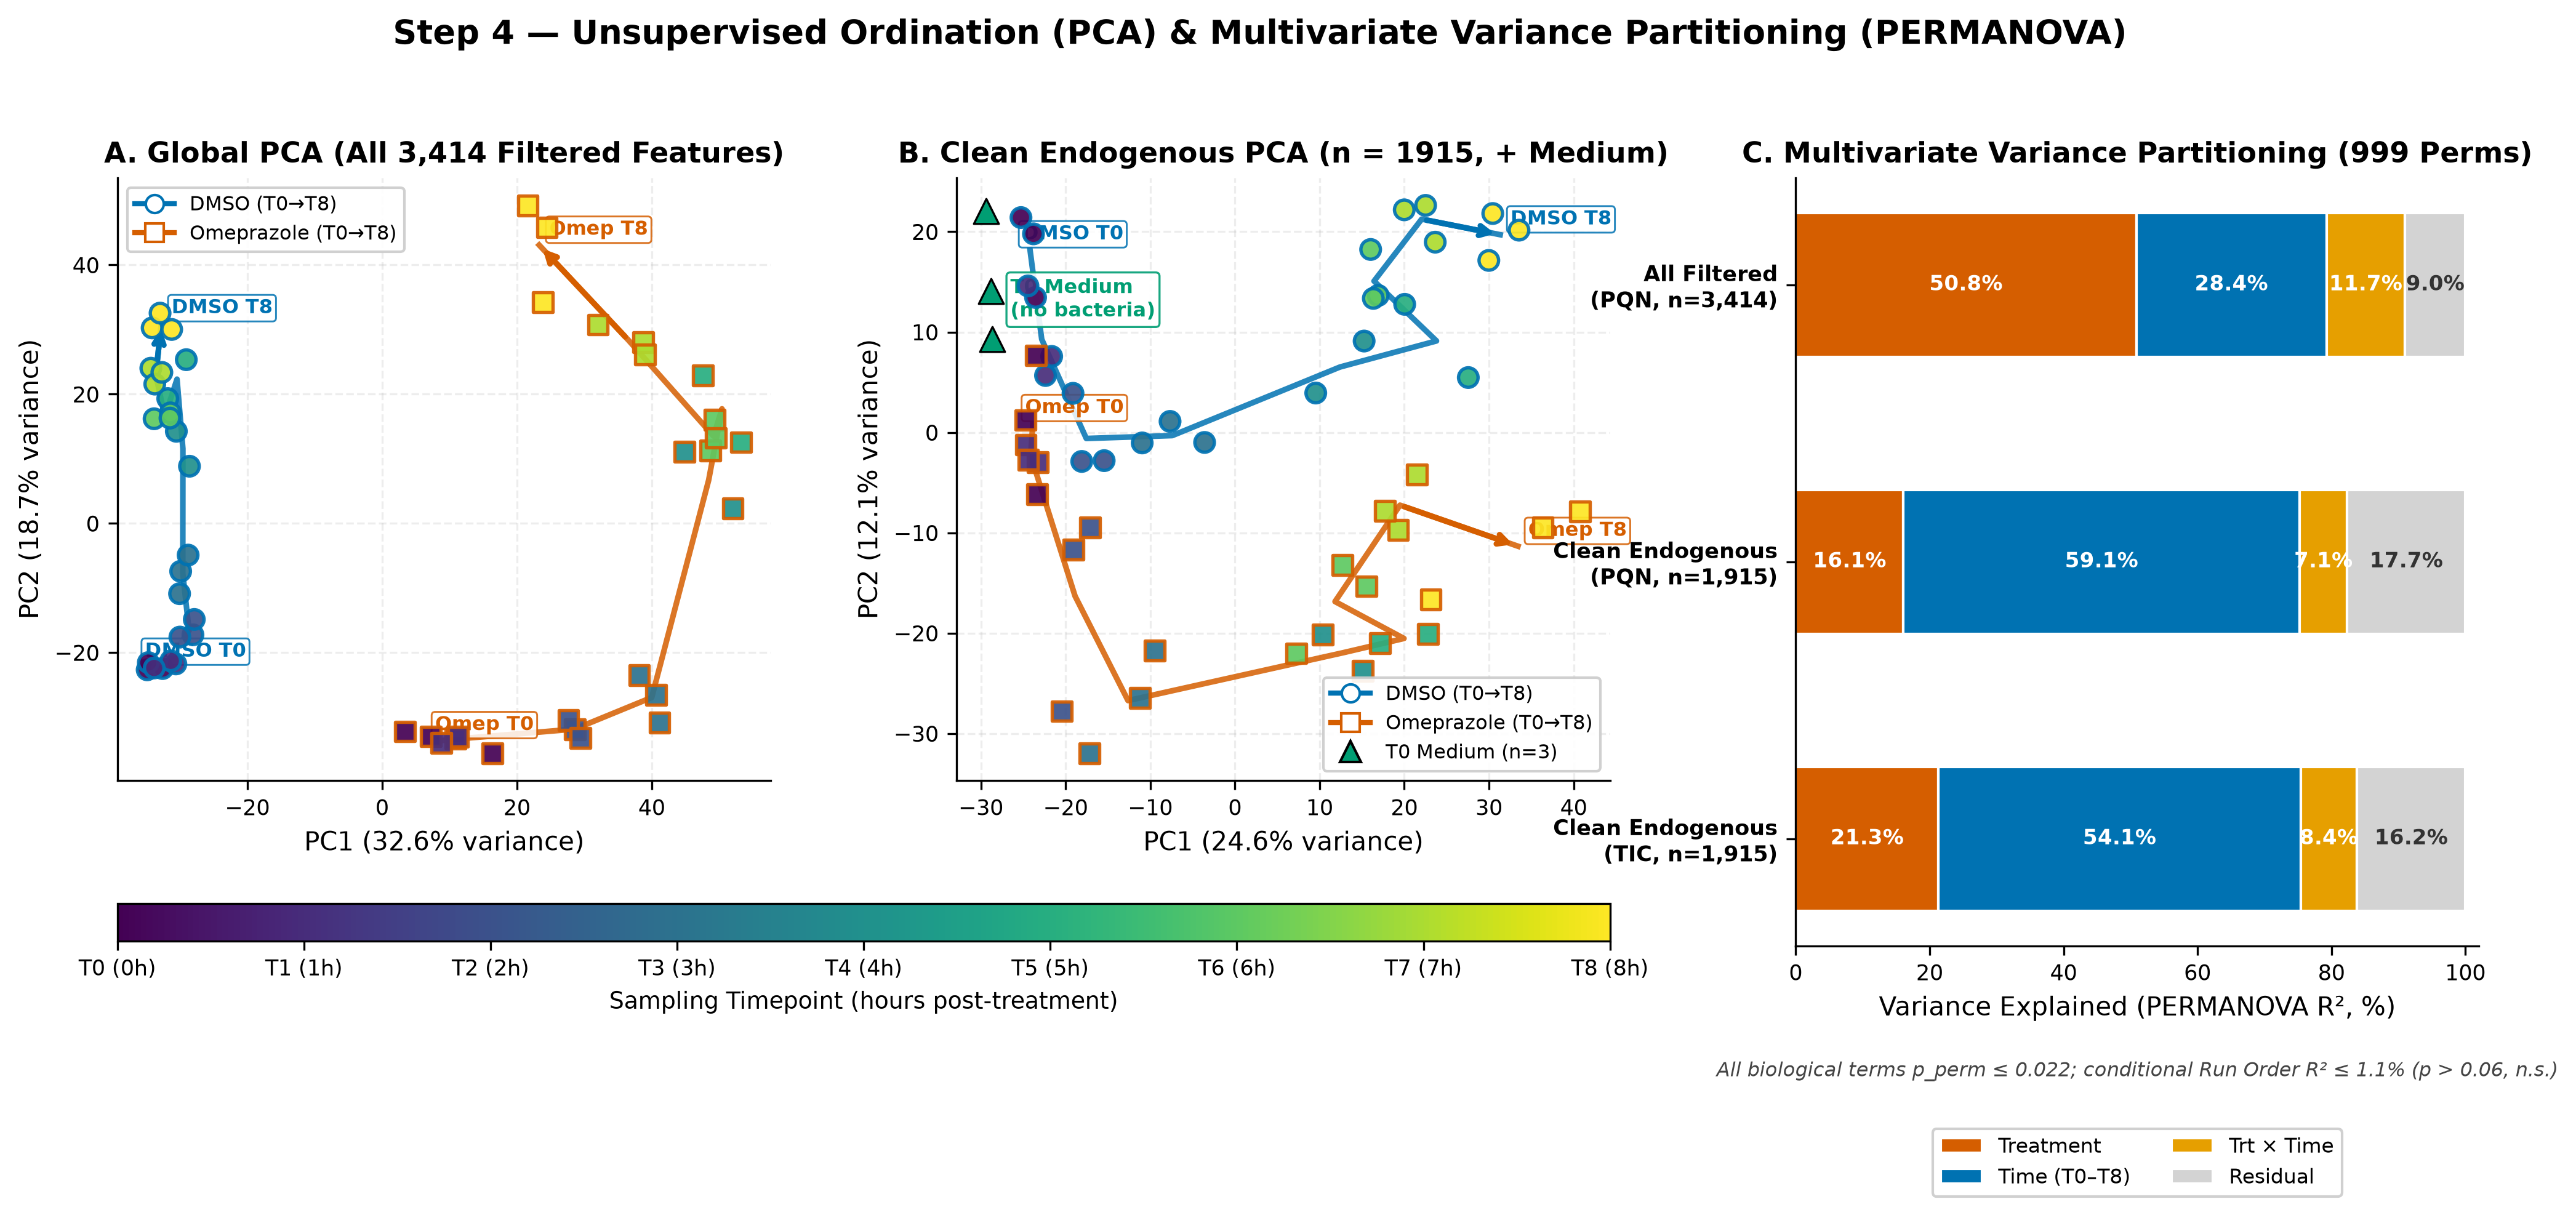

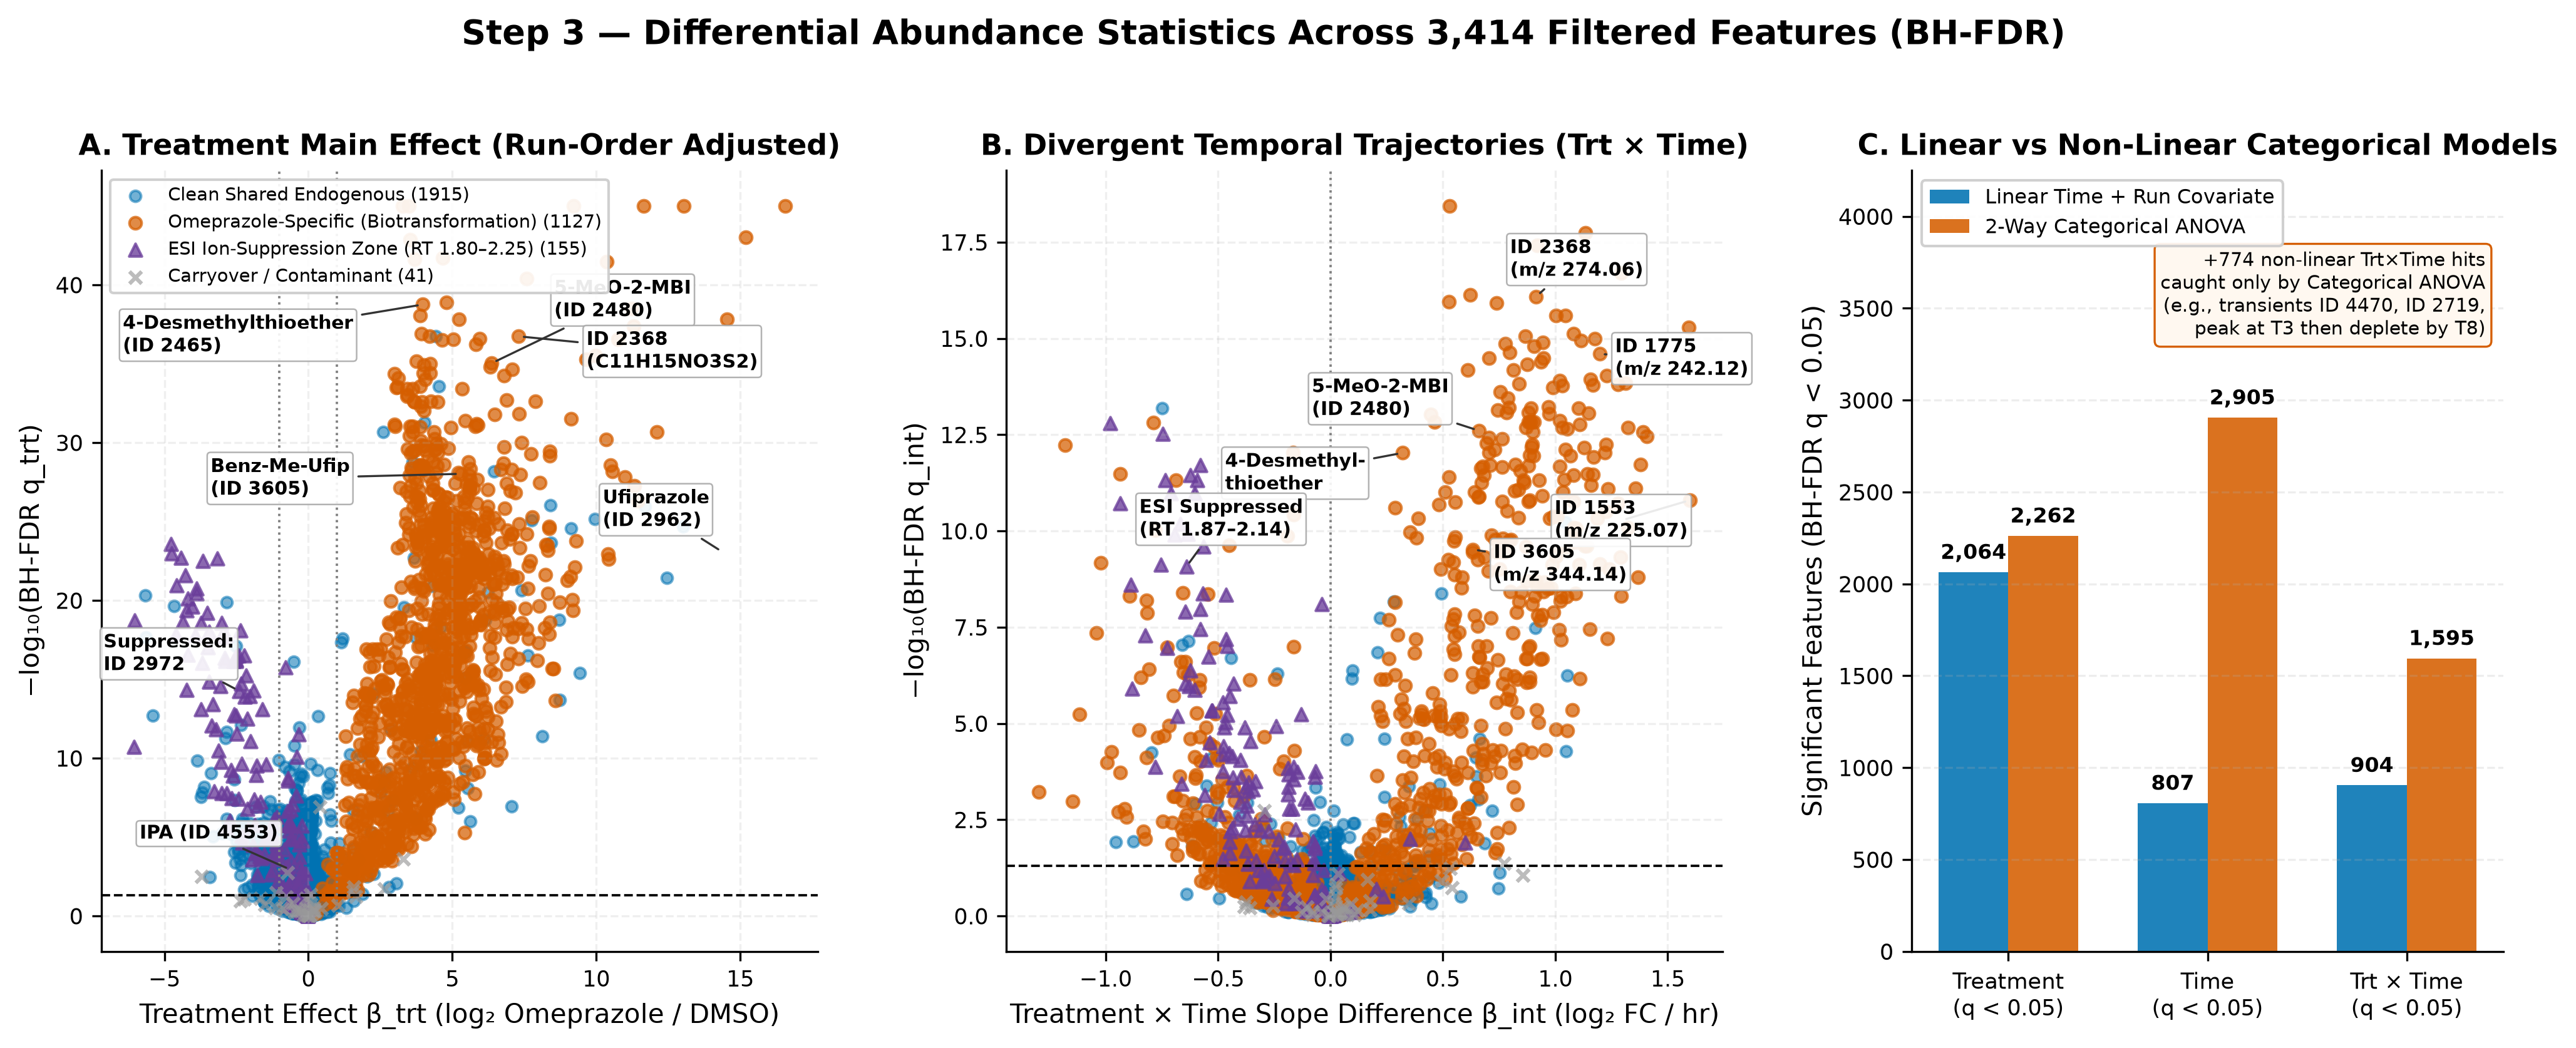

In [4]:
display(perm[["Feature_Set", "Term", "df", "R2", "pseudo_F", "p_perm"]].round(4))
display(Image(filename=str(FIGS / "fig03_pca_and_variance_partitioning.png"), width=1050))
display(Image(filename=str(FIGS / "fig04_statistical_volcano_and_model_comparison.png"), width=1050))

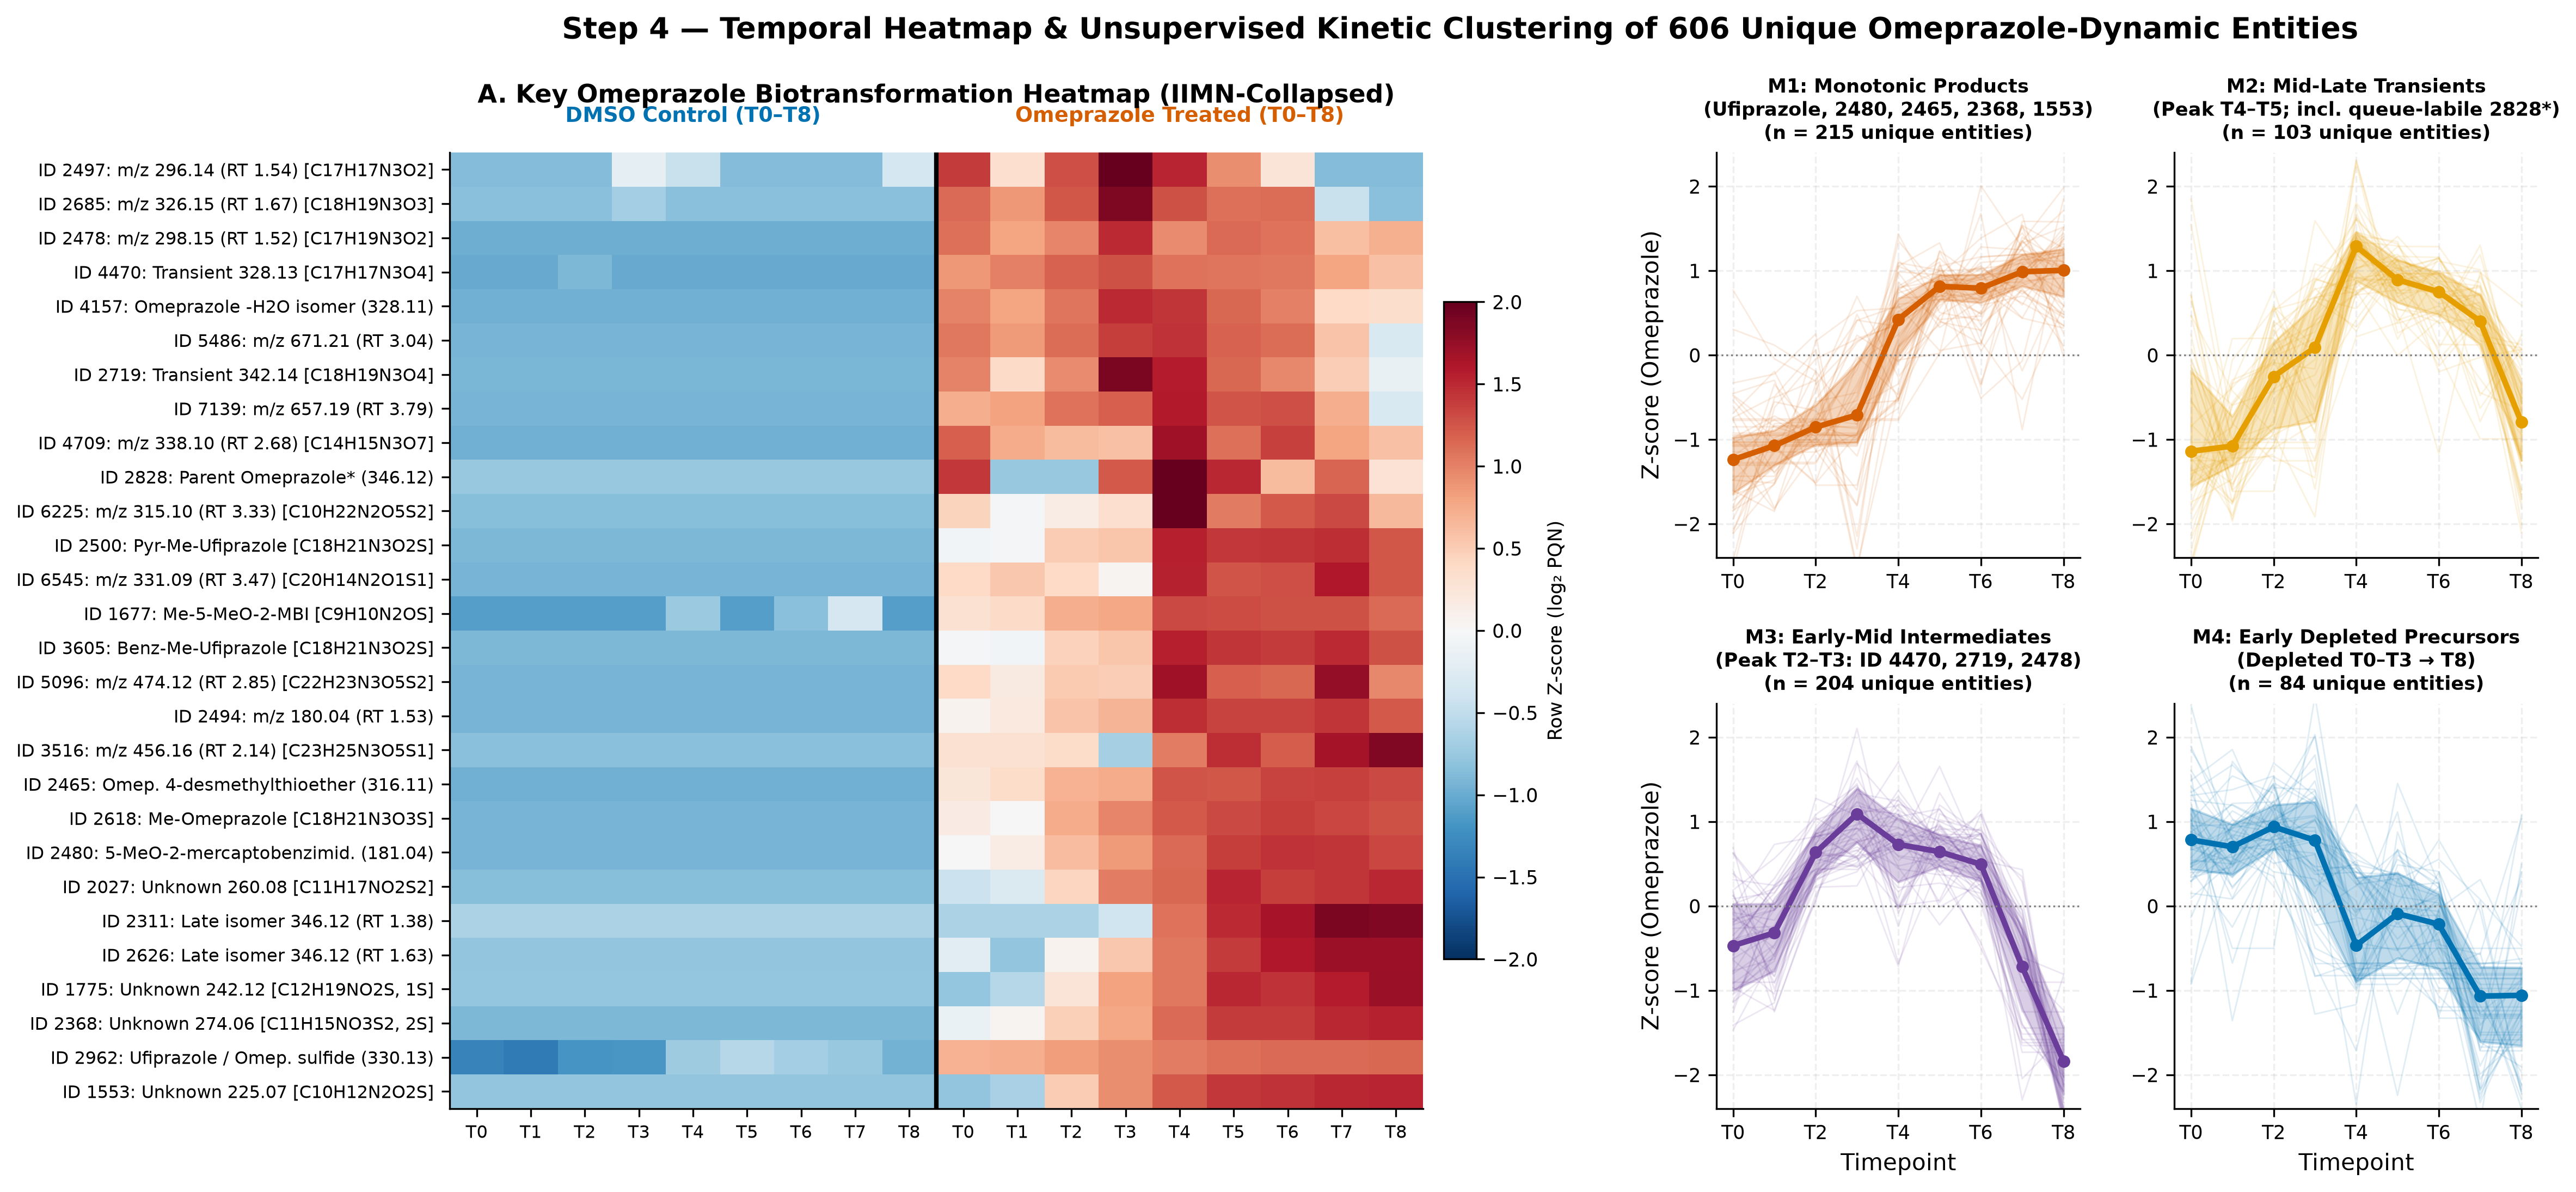

=== 5-Fold Stratified CV Classification Performance ===


ROC_AUC  \
                                                                         mean   
Task                                           Model                            
Growth Stage T0-2/T3-5/T6-8 (Clean Endogenous) L2 Logistic Regression    1.00   
                                               Random Forest             0.99   
Omeprazole vs DMSO (All Unique)                L1 Logistic Regression    1.00   
                                               Random Forest             1.00   
Omeprazole vs DMSO (Clean Endogenous)          L1 Logistic Regression    1.00   
                                               Random Forest             1.00   

                                                                              \
                                                                         std   
Task                                           Model                           
Growth Stage T0-2/T3-5/T6-8 (Clean Endogenous) L2 Logistic Regression  0.000   
                                               Random Forest           0.021   
Omeprazole vs DMSO (All Unique)                L1 Logistic Regression  0.000   
                                               Random Forest           0.000   
Omeprazole vs DMSO (Clean Endogenous)          L1 Logistic Regression  0.000   
                                               Random Forest           0.000   

                                                                      Balanced_Acc  \
                                                                              mean   
Task                                           Model                                 
Growth Stage T0-2/T3-5/T6-8 (Clean Endogenous) L2 Logistic Regression        1.000   
                                               Random Forest                 0.956   
Omeprazole vs DMSO (All Unique)                L1 Logistic Regression        1.000   
                                               Random Forest                 1.000   
Omeprazole vs DMSO (Clean Endogenous)          L1 Logistic Regression        1.000   
                                               Random Forest                 1.000   

                                                                              
                                                                         std  
Task                                           Model                          
Growth Stage T0-2/T3-5/T6-8 (Clean Endogenous) L2 Logistic Regression  0.000  
                                               Random Forest           0.099  
Omeprazole vs DMSO (All Unique)                L1 Logistic Regression  0.000  
                                               Random Forest           0.000  
Omeprazole vs DMSO (Clean Endogenous)          L1 Logistic Regression  0.000  
                                               Random Forest           0.000

=== Top 12 Prioritized Features (Annotated & Unannotated Dark Metabolome) ===


,mz,rt,feature_category,beta_trt,beta_int,spearman_time_omepr,rf_importance_trt,composite_priority_score,compound_name
row_id,,,,,,,,,
2618,360.137559,1.615378,Omeprazole_Specific,6.464433,0.584802,0.868487,0.008000,0.935624,NaN
2678,288.072150,1.661880,Omeprazole_Specific,7.894119,1.031100,0.928062,0.005548,0.933511,NaN
2480,181.043035,1.523150,Omeprazole_Specific,6.365478,0.659521,0.882800,0.004000,0.924146,37052-78-1
6908,482.132072,3.673055,Omeprazole_Specific,6.909662,-0.139179,0.034817,0.005000,0.921865,NaN
5486,671.210976,3.035226,Omeprazole_Specific,10.405657,-0.619851,-0.339658,0.003000,0.920689,NaN
1553,225.069606,0.861821,Omeprazole_Specific,8.234032,1.599984,0.985245,0.000500,0.918435,NaN
2368,274.056485,1.426299,Omeprazole_Specific,7.304250,0.914787,0.975258,0.003000,0.912766,NaN
2838,406.125326,1.783973,Omeprazole_Specific,6.258650,0.293296,0.357840,0.004500,0.912584,NaN
5974,735.155153,3.216367,Omeprazole_Specific,7.059480,-0.336720,-0.342366,0.004000,0.907881,NaN


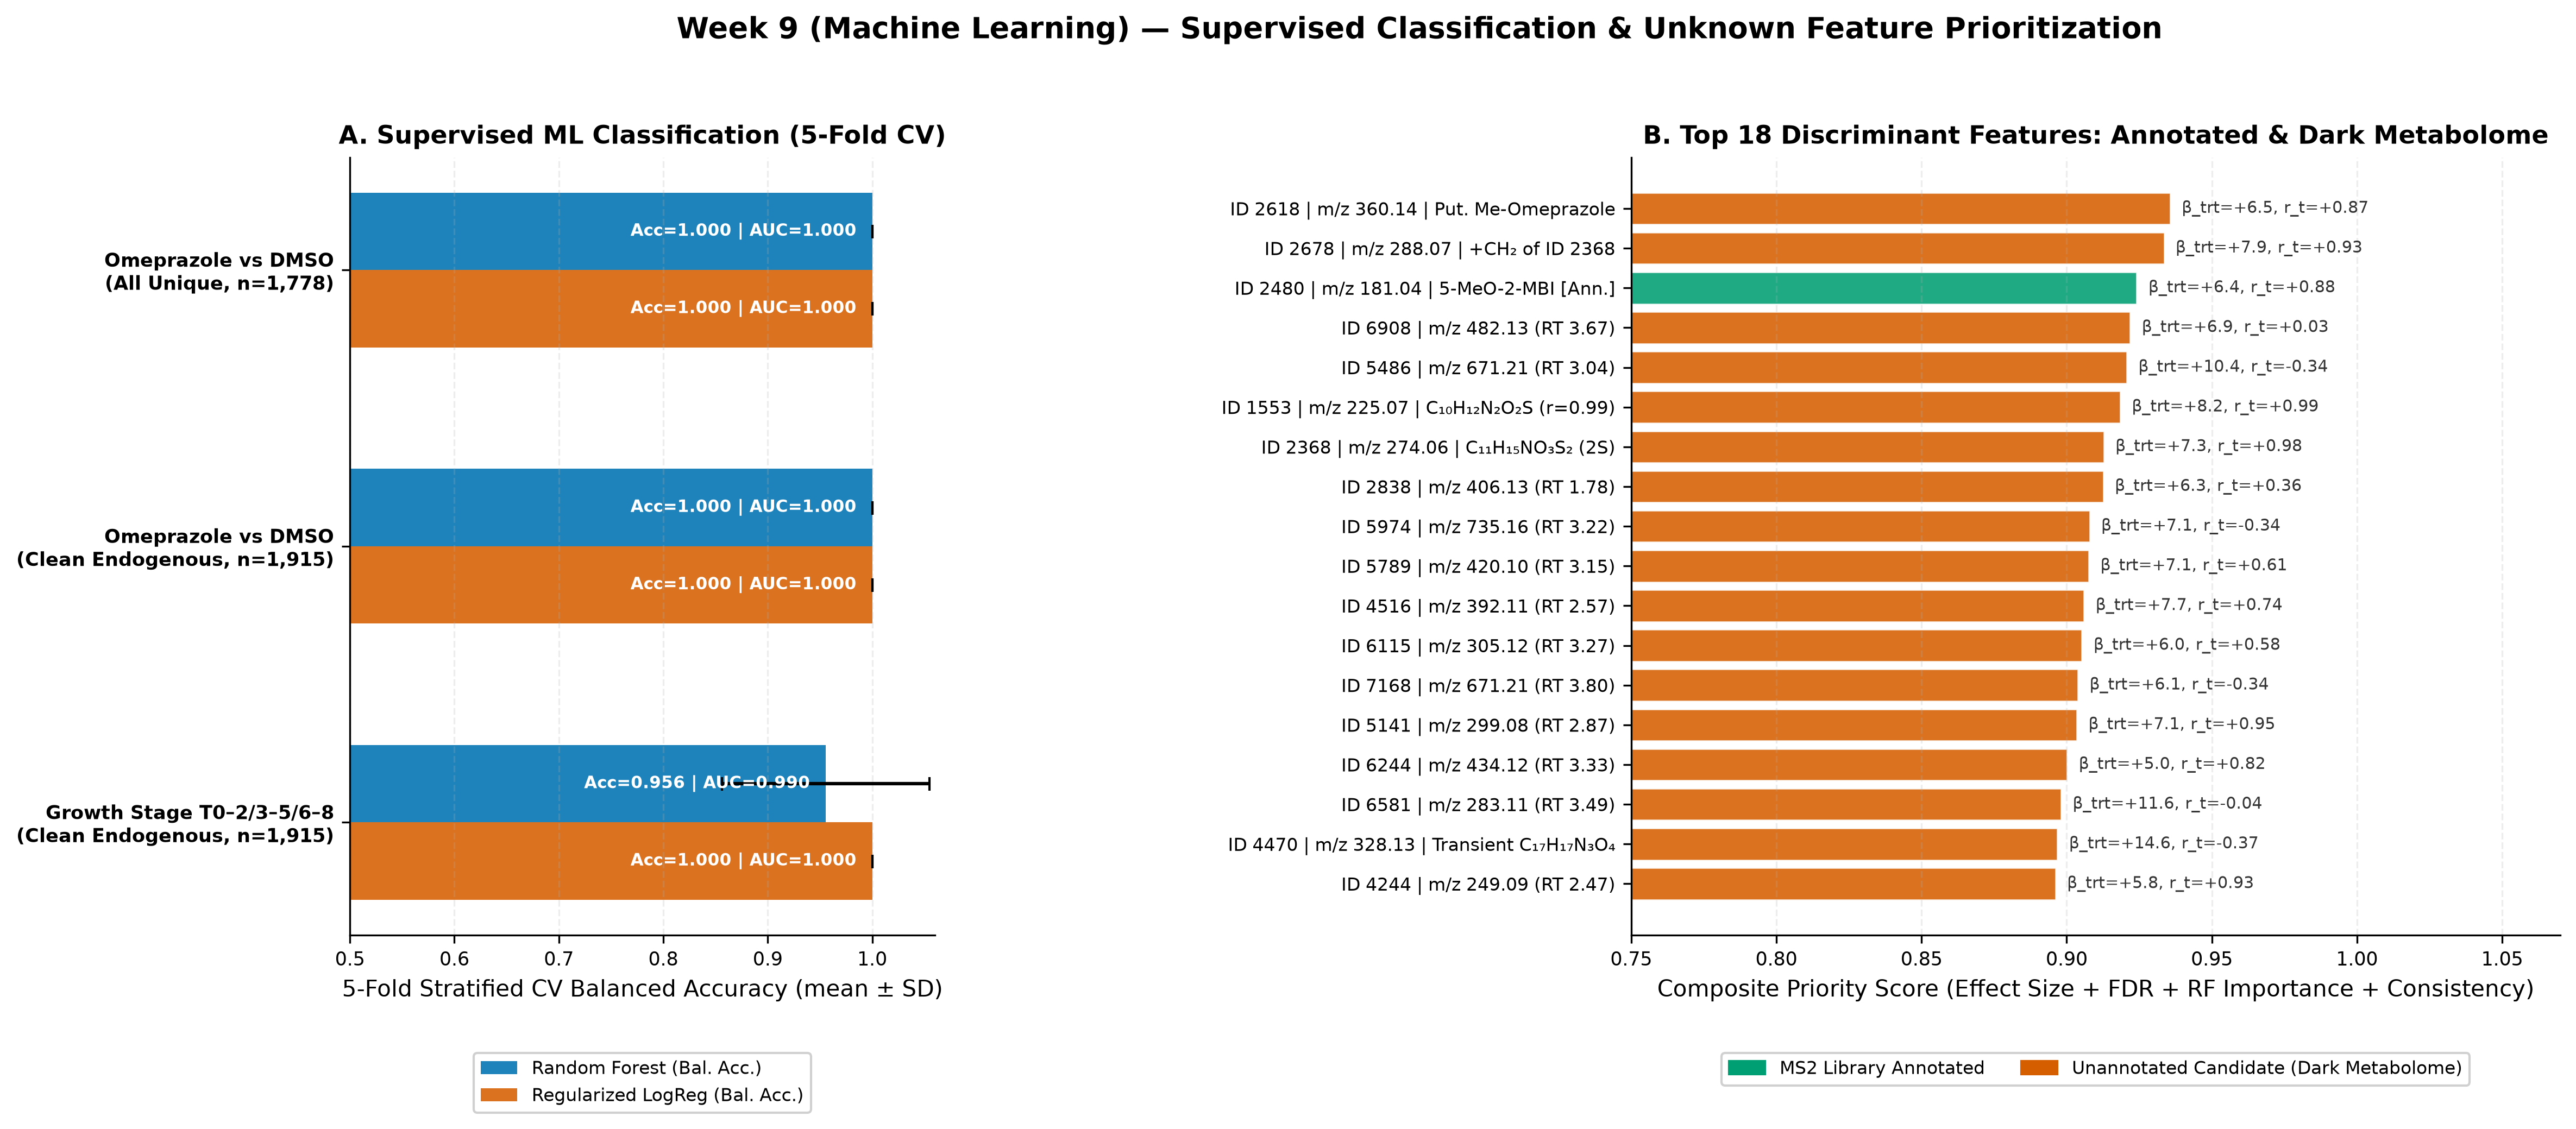

In [5]:
display(Image(filename=str(FIGS / "fig05_temporal_heatmap_and_kinetic_clusters.png"), width=1050))
print("=== 5-Fold Stratified CV Classification Performance ===")
display(ml_cv.groupby(["Task", "Model"])[["ROC_AUC", "Balanced_Acc"]].agg(["mean", "std"]).round(3))
print("=== Top 12 Prioritized Features (Annotated & Unannotated Dark Metabolome) ===")
display(ml_rank[["mz", "rt", "feature_category", "beta_trt", "beta_int", "spearman_time_omepr", "rf_importance_trt", "composite_priority_score", "compound_name"]].head(12))
display(Image(filename=str(FIGS / "fig06_ml_prioritization_known_and_unknown.png"), width=1050))